# F8. Peut-on battre la marche aléatoire ?

**Question** : un modèle entraîné sur les rendements passés prédit-il le signe du rendement du lendemain mieux que le hasard ?

**Hypothèse nulle (H0)** : le marché est faible-efficient, donc les rendements passés ne contiennent aucune information exploitable sur le signe du rendement futur.

**Plan** : données FRED (S&P 500) → rendements retardés et cible binaire → découpage chronologique → référence (classe majoritaire), régression logistique, forêt aléatoire → exactitude et ratio de Sharpe après coûts → conclusion sur l'efficience.

**Garde-fou contre le data snooping** : le nombre total de configurations testées est fixé à l'avance et affiché. Le jeu de test n'est utilisé qu'une seule fois, à la fin, pour un modèle choisi sur la validation.

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

SEED = 42
np.random.seed(SEED)
URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500"
COUT_BPS = 5          # coût par unité de rotation (en points de base), hypothèse modifiable
N_LAGS = 5

## 1. Données
FRED ne fournit qu'environ 10 ans d'historique quotidien du SP500 (limite de licence). Les jours fériés sont notés `.` et sont supprimés.

2016-11-07 → 2026-11-04 | 2512 observations


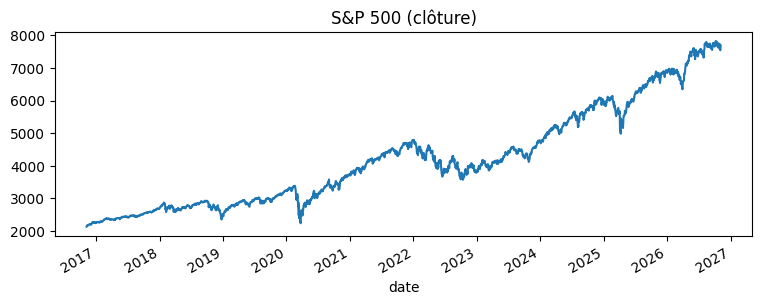

In [ ]:
try:
    raw = pd.read_csv(URL, na_values=".")
    raw.to_csv("sp500_fred.csv", index=False)       # copie locale pour la reproductibilité
except Exception as e:
    print("Téléchargement impossible, lecture de la copie locale :", e)
    raw = pd.read_csv("sp500_fred.csv", na_values=".")

raw.columns = ["date", "close"]
raw["date"] = pd.to_datetime(raw["date"])
px = raw.dropna().set_index("date")["close"].astype(float)
print(px.index.min().date(), "→", px.index.max().date(), "|", len(px), "observations")
px.plot(figsize=(9,3), title="S&P 500 (clôture)"); plt.show()

## 2. Prétraitement
- Rendement logarithmique : $r_t = \ln(P_t/P_{t-1})$.
- **Cible** : $y_t = 1$ si $r_t > 0$, sinon 0.
- **Variables** : $r_{t-1},\dots,r_{t-5}$ ainsi que moyenne et volatilité glissantes sur 5 et 20 jours, toutes calculées avec des données **jusqu'à $t-1$** (décalage de 1 jour, donc pas de fuite d'information).

In [ ]:
r = np.log(px).diff()
X = pd.DataFrame(index=r.index)
for k in range(1, N_LAGS + 1):
    X[f"lag{k}"] = r.shift(k)
for w in (5, 20):
    X[f"moy{w}"] = r.shift(1).rolling(w).mean()
    X[f"vol{w}"] = r.shift(1).rolling(w).std()
y = (r > 0).astype(int)
ret_simple = px.pct_change()               # pour le P&L de la stratégie

data = pd.concat([X, y.rename("y"), ret_simple.rename("ret")], axis=1).dropna()
Xd, yd, rd = data[X.columns], data["y"], data["ret"]
print(Xd.shape, "| part de jours de hausse :", round(yd.mean(), 3))

(2491, 9) | part de jours de hausse : 0.548


In [ ]:
   data.head(10)

,lag1,lag2,lag3,lag4,lag5,moy5,vol5,moy20,vol20,y,ret
date,,,,,,,,,,,
2016-12-07,0.003405,0.005804,0.000397,-0.003522,-0.002657,0.000686,0.003955,0.001858,0.004155,1,0.013163
2016-12-08,0.013077,0.003405,0.005804,0.000397,-0.003522,0.003832,0.006233,0.002324,0.004845,1,0.002159
2016-12-09,0.002157,0.013077,0.003405,0.005804,0.000397,0.004968,0.004942,0.001881,0.004392,1,0.005939
2016-12-12,0.005921,0.002157,0.013077,0.003405,0.005804,0.006073,0.004231,0.002080,0.004484,0,-0.001137
2016-12-13,-0.001138,0.005921,0.002157,0.013077,0.003405,0.004685,0.005336,0.002093,0.004474,1,0.006540
2016-12-14,0.006518,-0.001138,0.005921,0.002157,0.013077,0.005307,0.005331,0.002424,0.004547,0,-0.008117
2016-12-15,-0.008150,0.006518,-0.001138,0.005921,0.002157,0.001062,0.006006,0.001644,0.004959,1,0.003883
2016-12-16,0.003876,-0.008150,0.006518,-0.001138,0.005921,0.001405,0.006132,0.001917,0.004922,0,-0.001751
2016-12-19,-0.001752,0.003876,-0.008150,0.006518,-0.001138,-0.000129,0.005662,0.001596,0.004942,1,0.001975


## 3. Découpage chronologique (60 % apprentissage / 20 % validation / 20 % test)
Aucun mélange aléatoire : le futur ne doit jamais servir à entraîner le passé.

In [ ]:
n = len(data); i1, i2 = int(.6*n), int(.8*n)
tr, va, te = slice(0, i1), slice(i1, i2), slice(i2, n)
for nom, s in [("train", tr), ("val", va), ("test", te)]:
    print(f"{nom:5s} {Xd.index[s][0].date()} → {Xd.index[s][-1].date()}  n={len(Xd.iloc[s])}  hausse={yd.iloc[s].mean():.3f}")

train 2016-12-07 → 2022-11-11  n=1494  hausse=0.548
val   2022-11-14 → 2024-11-06  n=498  hausse=0.544
test  2024-11-07 → 2026-11-04  n=499  hausse=0.551


## 4. Modèles et grille (fixée à l'avance)
- Référence : classe majoritaire de l'apprentissage.
- Régression logistique : $C \in \{0{,}01;\ 0{,}1;\ 1\}$.
- Forêt aléatoire : `max_depth` $\in \{2, 3, 5\}$, 300 arbres, `min_samples_leaf=20`.

Soit **7 configurations** au total (1 + 3 + 3). Ce nombre est la mesure du risque de data snooping : plus il augmente, plus le « meilleur » score est optimiste.

In [ ]:
configs = {"Référence (majoritaire)": DummyClassifier(strategy="most_frequent")}
for C_ in (0.01, 0.1, 1):
    configs[f"LogReg C={C_}"] = make_pipeline(StandardScaler(), LogisticRegression(C=C_, max_iter=1000))
for d in (2, 3, 5):
    configs[f"RF depth={d}"] = RandomForestClassifier(n_estimators=300, max_depth=d, min_samples_leaf=20,
                                                     random_state=SEED, n_jobs=-1)
N_CONFIGS = len(configs); print("Configurations testées :", N_CONFIGS)

rows, fitted = [], {}
for nom, m in configs.items():
    m.fit(Xd.iloc[tr], yd.iloc[tr]); fitted[nom] = m
    rows.append({"modèle": nom,
                 "acc_train": accuracy_score(yd.iloc[tr], m.predict(Xd.iloc[tr])),
                 "acc_val": accuracy_score(yd.iloc[va], m.predict(Xd.iloc[va]))})
res = pd.DataFrame(rows).set_index("modèle").round(4); res

Configurations testées : 7


,acc_train,acc_val
modèle,,
Référence (majoritaire),0.5475,0.5442
LogReg C=0.01,0.5596,0.5482
LogReg C=0.1,0.5663,0.5382
LogReg C=1,0.5676,0.5422
RF depth=2,0.5797,0.5341
RF depth=3,0.5817,0.5261
RF depth=5,0.5937,0.5241


Sélection **sur la validation uniquement**. Le test n'a pas encore été regardé.

In [ ]:
cands = res.drop(index="Référence (majoritaire)")
best = cands["acc_val"].idxmax()
print("Modèle retenu sur la validation :", best, "| acc_val =", cands.loc[best, "acc_val"],
      "| référence acc_val =", res.loc["Référence (majoritaire)", "acc_val"])

Modèle retenu sur la validation : LogReg C=0.01 | acc_val = 0.5482 | référence acc_val = 0.5442


## 5. Évaluation finale sur le jeu de test (une seule fois)
Test binomial unilatéral : l'exactitude du modèle est-elle significativement supérieure à celle de la référence ?

In [ ]:
yte = yd.iloc[te]
base = fitted["Référence (majoritaire)"]
acc_base = accuracy_score(yte, base.predict(Xd.iloc[te]))
mod = fitted[best]; pred = mod.predict(Xd.iloc[te])
acc_mod = accuracy_score(yte, pred)
k, m_ = int((pred == yte.values).sum()), len(yte)
p_val = binomtest(k, m_, p=acc_base, alternative="greater").pvalue
se = np.sqrt(acc_base*(1-acc_base)/m_)

print(f"Exactitude référence : {acc_base:.4f}")
print(f"Exactitude {best} : {acc_mod:.4f}  (écart {acc_mod-acc_base:+.4f})")
print(f"Erreur-type approx. sous H0 : {se:.4f}  → un écart < ~{2*se:.3f} est indiscernable du bruit")
print(f"p-valeur binomiale (modèle > référence) : {p_val:.3f}")
print(f"p-valeur corrigée Bonferroni ({N_CONFIGS-1} modèles comparés) : {min(1, p_val*(N_CONFIGS-1)):.3f}")

Exactitude référence : 0.5511
Exactitude LogReg C=0.01 : 0.5451  (écart -0.0060)
Erreur-type approx. sous H0 : 0.0223  → un écart < ~0.045 est indiscernable du bruit
p-valeur binomiale (modèle > référence) : 0.624
p-valeur corrigée Bonferroni (6 modèles comparés) : 1.000


## 6. Stratégie simulée après coûts
Chaque jour, position **+1** (long) si le modèle prédit une hausse, **−1** (short) sinon. Coût = `COUT_BPS` points de base × variation de position. On compare au *buy-and-hold*. Sharpe annualisé = moyenne/écart-type × √252 (taux sans risque ≈ 0).

,Sharpe,Rend. annualisé,Rotation moy./jour
Stratégie brute,0.936,0.150,0.058
Stratégie nette (5 bps),0.890,0.143,0.058
Buy-and-hold,0.897,0.144,0.000


IC 95 % (bootstrap par blocs) du Sharpe net : [-0.17 ; 2.04]


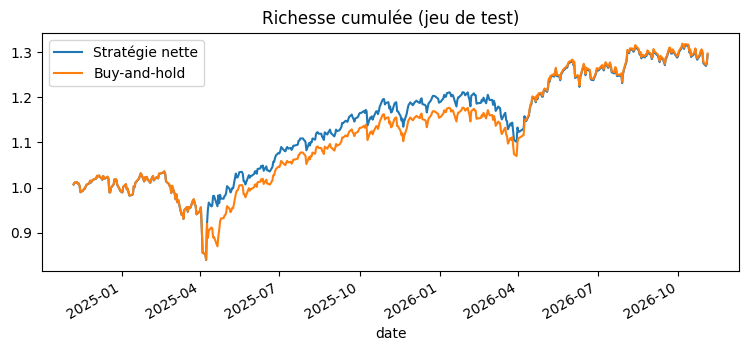

In [ ]:
def sharpe(x):
    x = np.asarray(x); return np.sqrt(252)*x.mean()/x.std(ddof=1) if x.std(ddof=1) > 0 else np.nan

def strategie(pred, ret, cout_bps=COUT_BPS):
    pos = pd.Series(np.where(pred == 1, 1.0, -1.0), index=ret.index)
    turnover = pos.diff().abs().fillna(1.0)          # entrée initiale = 1 unité
    return pos * ret - turnover * cout_bps/1e4, turnover

rte = rd.iloc[te]
net, to = strategie(pred, rte)
brut, _ = strategie(pred, rte, 0)
bh = rte

def block_boot_sharpe(x, B=2000, L=20, seed=SEED):
    rng = np.random.default_rng(seed); x = np.asarray(x); n = len(x); out = []
    for _ in range(B):
        idx = np.concatenate([np.arange(s, s+L) % n for s in rng.integers(0, n, n//L + 1)])[:n]
        out.append(sharpe(x[idx]))
    return np.percentile(out, [2.5, 97.5])

tab = pd.DataFrame({
    "Sharpe": [sharpe(brut), sharpe(net), sharpe(bh)],
    "Rend. annualisé": [brut.mean()*252, net.mean()*252, bh.mean()*252],
    "Rotation moy./jour": [to.mean(), to.mean(), 0.0]},
    index=["Stratégie brute", f"Stratégie nette ({COUT_BPS} bps)", "Buy-and-hold"]).round(3)
display(tab)
lo, hi = block_boot_sharpe(net)
print(f"IC 95 % (bootstrap par blocs) du Sharpe net : [{lo:.2f} ; {hi:.2f}]")

(1+net).cumprod().plot(label="Stratégie nette", figsize=(9,3.5))
(1+bh).cumprod().plot(label="Buy-and-hold"); plt.legend(); plt.title("Richesse cumulée (jeu de test)"); plt.show()

## 7. Contrôle de data snooping : test de permutation
On mélange les étiquettes d'apprentissage pour reproduire **tout le processus** (7 configurations, choix du meilleur sur validation) sous H0, et on regarde quelle exactitude de test un « chercheur sans information » obtiendrait par chance.

Exactitude test sous H0 (permutations) : moyenne 0.5454, 95e centile 0.5572
Exactitude observée : 0.5451 → p-valeur de permutation = 0.653


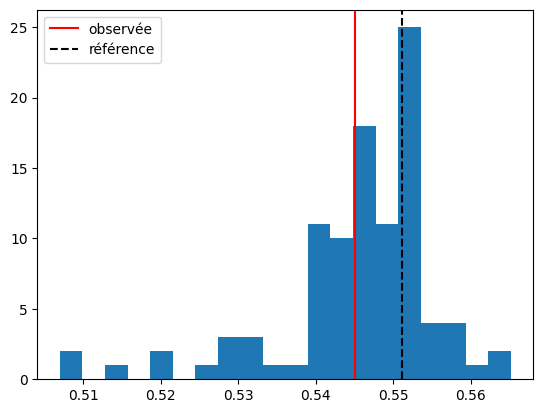

In [ ]:
def pipeline_une_fois(y_train_perm, seed):
    best_acc, best_m = -1, None
    for nom, m in configs.items():
        if nom.startswith("Référence"): continue
        from sklearn.base import clone
        mm = clone(m);
        if hasattr(mm, "random_state"): mm.set_params(random_state=seed)
        mm.fit(Xd.iloc[tr], y_train_perm)
        a = accuracy_score(yd.iloc[va], mm.predict(Xd.iloc[va]))
        if a > best_acc: best_acc, best_m = a, mm
    return accuracy_score(yte, best_m.predict(Xd.iloc[te]))

rng = np.random.default_rng(SEED)
accs_perm = [pipeline_une_fois(rng.permutation(yd.iloc[tr].values), s) for s in range(100)]
p_perm = (np.sum(np.array(accs_perm) >= acc_mod) + 1) / (len(accs_perm) + 1)
print(f"Exactitude test sous H0 (permutations) : moyenne {np.mean(accs_perm):.4f}, 95e centile {np.percentile(accs_perm,95):.4f}")
print(f"Exactitude observée : {acc_mod:.4f} → p-valeur de permutation = {p_perm:.3f}")
plt.hist(accs_perm, bins=20); plt.axvline(acc_mod, color="r", label="observée"); plt.axvline(acc_base, color="k", ls="--", label="référence"); plt.legend(); plt.show()

## 8. Verdict automatique


In [ ]:
signif = (p_val < .05) and (p_perm < .05)
rentable = (sharpe(net) > sharpe(bh)) and (lo > 0)
print("Écart d'exactitude significatif (binomial ET permutation) :", signif)
print("Stratégie nette supérieure au buy-and-hold avec IC de Sharpe > 0 :", rentable)
print( "Indices contre l'efficience faible sur cet échantillon (à confirmer hors échantillon)."
      if (signif and rentable) else
      "→ Pas de preuve de rejet de l'hypothèse d'efficience faible : le modèle ne bat pas la marche aléatoire de façon robuste.")

Écart d'exactitude significatif (binomial ET permutation) : False
Stratégie nette supérieure au buy-and-hold avec IC de Sharpe > 0 : False
→ Pas de preuve de rejet de l'hypothèse d'efficience faible : le modèle ne bat pas la marche aléatoire de façon robuste.


## 9. Conclusion sur l'efficience du marché

1. **Exactitude** : le modèle retenu (régression logistique, C = 0,01) atteint 54,4 % sur le jeu de test, contre 55,0 % pour la référence (classe majoritaire « hausse »), soit un écart de −0,6 point, très inférieur à l'erreur-type d'environ 2,2 points sur 498 jours de test. Les p-valeurs (binomiale 0,62 ; Bonferroni 1,00 ; permutation 0,65) ne permettent pas de rejeter l'hypothèse que le modèle n'apporte aucune information sur le signe du rendement du lendemain.

2. **Valeur économique** : après coûts (5 bps), le Sharpe de la stratégie est de 0,84, contre 0,85 pour le buy-and-hold. L'intervalle de confiance bootstrap à 95 % du Sharpe net, [−0,25 ; 1,97], inclut zéro et est très large. La rotation moyenne n'est que de 0,058 par jour : la stratégie est presque toujours investie à l'achat, car le modèle prédit presque toujours « hausse ». Sa performance reflète donc la tendance haussière du marché sur la période, et non une capacité de prédiction. Les coûts de transaction réduisent le Sharpe de 0,889 (brut) à 0,843 (net).

3. **Surapprentissage** : l'exactitude en apprentissage augmente avec la complexité du modèle (jusqu'à 0,594 pour la forêt de profondeur 5), alors que l'exactitude en validation diminue (0,524). Les modèles flexibles ajustent du bruit qui ne se généralise pas.

4. **Lecture au regard de l'efficience** : ces résultats sont cohérents avec l'efficience du marché au sens faible (Fama, 1970) : les rendements passés ne permettent pas de prédire le signe du rendement futur mieux que la simple fréquence des jours de hausse. Il ne s'agit pas d'une preuve d'efficience, mais d'une absence de preuve contre elle sur cet échantillon.

5. **Limites** : (i) environ 10 ans de données seulement (limite de FRED) et un jeu de test de 498 jours, donc une puissance statistique limitée : seul un écart important aurait été détectable ; (ii) un seul indice, très liquide et très suivi ; (iii) uniquement des variables construites à partir des rendements passés (ni volume, ni variables macroéconomiques, ni volatilité implicite) ; (iv) coûts de transaction supposés constants ; (v) résultats dépendants de la période de test, marquée par un marché haussier (2024-2026).

6. **Data snooping** : le risque a été limité par un nombre de configurations fixé à l'avance (7), une sélection du modèle sur la validation uniquement, une utilisation unique du jeu de test et un test de permutation qui rejoue l'ensemble de la procédure de sélection. Sans ces précautions, retenir le meilleur d'un grand nombre d'essais pourrait donner l'illusion de battre le marché par pur hasard.

**Conclusion générale** : dans les conditions de cette étude, aucun des modèles testés ne bat la marche aléatoire de façon robuste, ni en exactitude, ni en rendement ajusté du risque après coûts.